# Ion-channel inference across initial conditions and stochastic seeds

Robustness analysis of PST and GS-ST across kinetic initial conditions and stochastic seeds, using reduced trajectory ensembles (Figure 5).

The default `CFG.cache_only = False` computes missing runs and reuses compatible results in `ion_channel_multiinit/`. Set it to `True` to analyze saved runs without starting training. Dataset attribution is provided in [Data sources](../DATA_SOURCES.md).

Run from the `IonChannelMR/` directory using the `PST (Python 3.11)` kernel. See [Running the notebooks](../docs/RUNNING.md) for execution settings and result reuse.

**Authors:** Jose M. G. Vilar$^{1,2}$ and Leonor Saiz$^{3}$  
$^1$ Biofisika Institute (CSIC, UPV/EHU), University of the Basque Country, P.O. Box 644, 48080 Bilbao, Spain  
$^2$ IKERBASQUE, Basque Foundation for Science, 48011 Bilbao, Spain  
$^3$ Department of Biomedical Engineering, University of California, 451 East Health Sciences Drive, Davis, CA 95616, USA

**Preprint:** J. M. G. Vilar and L. Saiz, *Propensity Straight-Through Gradients for Discrete Stochastic Systems*, arXiv:2608.25631 [q-bio.QM] (2026).  
**DOI:** [https://doi.org/10.48550/arXiv.2608.25631](https://doi.org/10.48550/arXiv.2608.25631)


In [ ]:
# =============================================================================
# 1. Imports and TensorFlow setup
# =============================================================================

import gc
import json
import math
import os
import pickle
import platform
import time
import urllib.request
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import tensorflow as tf

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except (RuntimeError, ValueError):
        pass

tf.get_logger().setLevel("ERROR")

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))


Python: 3.11.15
TensorFlow: 2.20.0
NumPy: 2.4.6


In [ ]:
# =============================================================================
# 2. Experiment configuration
# =============================================================================

@dataclass(frozen=True)
class ExperimentConfig:
    # Reduced-ensemble robustness protocol
    epochs: int = 800//2
    trajectories_per_epoch: int = 10_000
    ssa_steps: int = 40
    validation_trajectories: int = 300_000
    n_channels: int = 2

    # Matched optimizer schedule
    pst_lr_initial: float = 0.05
    gsst_lr_initial: float = 0.05
    lr_final_fraction: float = 0.01  # 0.05 -> 0.0005

    # GS-ST reaction-selection temperature only
    gsst_tau_initial: float = 0.1
    gsst_tau_final: float = 0.001

    # Initial-parameter robustness design
    n_initializations: int = 10
    base_initial_rate: float = 0.25
    multiplier_min: float = 0.2 / 0.25
    multiplier_max: float = 1.0 / 0.25
    initialization_design_seed: int = 20260824

    # Stochastic replication
    replicates: int = 3
    base_run_seed: int = 43
    replicate_seed_stride: int = 97_377

    # Figure 4 diagnostic retained for comparison with the single-run benchmark.
    loss_smooth_window: int = 10
    loss_terminal_window: int = 50
    stabilization_tolerances: tuple = (0.20, 0.10, 0.05, 0.02)

    # Stabilization diagnostic for noisy reduced-ensemble histories.
    robust_smooth_window: int = 10
    robust_terminal_window: int = 50
    robust_primary_persistence: int = 50
    robust_persistence_sensitivity: tuple = (25, 50, 100)

    # Common-loss diagnostic for the reduced-ensemble comparison (analysis only).
    common_loss_smooth_window: int = 10
    common_loss_terminal_window: int = 50
    common_loss_primary_multiplier: float = 2.0
    common_loss_target_multipliers: tuple = (4.0, 3.0, 2.0, 1.5, 1.25, 1.10)
    common_loss_primary_persistence: int = 10
    common_loss_persistence_sensitivity: tuple = (5, 10, 25)

    # Endpoint parameter summary
    parameter_terminal_window: int = 50

    # Cache behavior.
    # With cache_only=True, missing caches
    # cause a clear error instead of launching an expensive training run.
    # Set False when a from-scratch calculation is intended.
    cache_only: bool = False

    # Files
    data_filename: str = "HEK293_Cell01_40mV_100s_raw_DET_IDEl.xlsx"

    # The output directory identifies the archived training cache so completed
    # training .pkl files can be reused.
    output_dir: str = "ion_channel_multiinit"


CFG = ExperimentConfig()

# Public fallback for the same processed experimental file used by the
# single-run benchmark. A local file with CFG.data_filename is preferred.
DATA_URL = (
    "https://raw.githubusercontent.com/CTMCDL/codeExactDL/main/"
    "IonChannel/HEK293_Cell01_40mV_100s_raw_DET_IDEl.xlsx"
)

OUTPUT_DIR = Path(CFG.output_dir)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Analysis products are separated from the training cache.
ANALYSIS_DIR = OUTPUT_DIR / "actual_results_si_analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

print(CFG)

if not math.isclose(CFG.pst_lr_initial, CFG.gsst_lr_initial):
    print(
        "\nNOTE: PST and GS-ST learning rates are intentionally UNMATCHED: "
        f"{CFG.pst_lr_initial} vs {CFG.gsst_lr_initial}."
    )
else:
    print("\nPST and GS-ST learning rates are matched.")

print("Cache-only analysis mode:", CFG.cache_only)
print("Analysis directory:", ANALYSIS_DIR.name)

ExperimentConfig(epochs=400, trajectories_per_epoch=10000, ssa_steps=40, validation_trajectories=300000, n_channels=2, pst_lr_initial=0.05, gsst_lr_initial=0.05, lr_final_fraction=0.01, gsst_tau_initial=0.1, gsst_tau_final=0.001, n_initializations=10, base_initial_rate=0.25, multiplier_min=0.8, multiplier_max=4.0, initialization_design_seed=20260824, replicates=3, base_run_seed=43, replicate_seed_stride=97377, loss_smooth_window=10, loss_terminal_window=50, stabilization_tolerances=(0.2, 0.1, 0.05, 0.02), robust_smooth_window=10, robust_terminal_window=50, robust_primary_persistence=50, robust_persistence_sensitivity=(25, 50, 100), common_loss_smooth_window=10, common_loss_terminal_window=50, common_loss_primary_multiplier=2.0, common_loss_target_multipliers=(4.0, 3.0, 2.0, 1.5, 1.25, 1.1), common_loss_primary_persistence=10, common_loss_persistence_sensitivity=(5, 10, 25), parameter_terminal_window=50, cache_only=False, data_filename='HEK293_Cell01_40mV_100s_raw_DET_IDEl.xlsx', output

### Protocol summary

The next cell displays the active reduced-ensemble configuration, including the Figure 4 stabilization diagnostic and the common-loss analysis used in Figure 5. Both analyses use the training histories generated below.


In [ ]:
# =============================================================================
# 3. Protocol audit
# =============================================================================

print("Protocol audit")
print("--------------")
print(f"epochs                  : {CFG.epochs}")
print(f"trajectories / epoch    : {CFG.trajectories_per_epoch:,}")
print(f"SSA event slots         : {CFG.ssa_steps}")
print(f"validation trajectories : {CFG.validation_trajectories:,}")
print(f"PST initial LR          : {CFG.pst_lr_initial}")
print(f"GS-ST initial LR        : {CFG.gsst_lr_initial}")
print(
    "LR endpoints           : "
    f"PST {CFG.pst_lr_initial:g} -> "
    f"{CFG.pst_lr_initial * CFG.lr_final_fraction:g}; "
    f"GS-ST {CFG.gsst_lr_initial:g} -> "
    f"{CFG.gsst_lr_initial * CFG.lr_final_fraction:g}"
)
print(
    "GS-ST tau              : "
    f"{CFG.gsst_tau_initial:g} -> {CFG.gsst_tau_final:g}"
)
print("PST estimator tau       : none")

print("\nLegacy Figure-4 diagnostic")
print(
    f"  trailing mean={CFG.loss_smooth_window}; "
    f"terminal mean={CFG.loss_terminal_window}; "
    "must remain below thereafter"
)

print("\nReduced-ensemble SI common-loss diagnostic")
print(
    f"  trailing median={CFG.common_loss_smooth_window}; "
    f"pooled terminal scale from final "
    f"{CFG.common_loss_terminal_window} epochs"
)
print(
    f"  primary common target="
    f"{CFG.common_loss_primary_multiplier:g} x pooled terminal scale"
)
print(
    f"  primary persistence={CFG.common_loss_primary_persistence} epochs"
)
print(
    "  target multipliers:",
    CFG.common_loss_target_multipliers,
)
print(
    "  persistence sensitivity:",
    CFG.common_loss_persistence_sensitivity,
)


Protocol audit
--------------
epochs                  : 400
trajectories / epoch    : 10,000
SSA event slots         : 40
validation trajectories : 300,000
PST initial LR          : 0.05
GS-ST initial LR        : 0.05
LR endpoints           : PST 0.05 -> 0.0005; GS-ST 0.05 -> 0.0005
GS-ST tau              : 0.1 -> 0.001
PST estimator tau       : none

Legacy Figure-4 diagnostic
  trailing mean=10; terminal mean=50; must remain below thereafter

Reduced-ensemble SI common-loss diagnostic
  trailing median=10; pooled terminal scale from final 50 epochs
  primary common target=2 x pooled terminal scale
  primary persistence=10 epochs
  target multipliers: (4.0, 3.0, 2.0, 1.5, 1.25, 1.1)
  persistence sensitivity: (5, 10, 25)


In [ ]:
# =============================================================================
# 4. Ion-channel model, PST/GS-ST estimators, simulators, readout, and loss
#
# Shares the model and estimator definitions in IonChannel-PST.ipynb.
# Training uses the non-XLA simulator; exact validation and readout use XLA.
# =============================================================================

NUM_SPECIES = 3
NUM_REACTIONS = 3
N_CHANNELS = 2

# Closed -> Open, Open -> Closed, Open -> Inactivated.
S = tf.constant(
    [
        [-1.0,  1.0,  0.0],
        [ 1.0, -1.0,  0.0],
        [ 0.0, -1.0,  1.0],
    ],
    dtype=tf.float32,
)


@tf.function
def propensity_fn(states, k_open, k_close, k_inact):
    """Mass-action propensities for C <-> O -> I."""
    states = tf.maximum(states, 0.0)
    n_closed = states[:, 0]
    n_open = states[:, 1]

    return tf.stack(
        [
            k_open * n_closed,
            k_close * n_open,
            k_inact * n_open,
        ],
        axis=1,
    )


# ---------------------------------------------------------------------
# Reaction-selection estimators
# ---------------------------------------------------------------------
def stgs_estimator(logits, tau=0.5):
    """Hard exact forward draw; Gumbel--Softmax backward surrogate."""
    u = tf.random.uniform(
        tf.shape(logits),
        minval=1e-20,
        maxval=1.0,
        dtype=logits.dtype,
    )
    gumbel = -tf.math.log(-tf.math.log(u))

    hard_idx = tf.argmax(logits + gumbel, axis=-1)
    y_hard = tf.one_hot(
        hard_idx,
        depth=tf.shape(logits)[-1],
        dtype=logits.dtype,
    )

    y_soft = tf.nn.softmax((logits + gumbel) / tau, axis=-1)
    return y_soft + tf.stop_gradient(y_hard - y_soft)


def pst_estimator(logits):
    """Propensity-based straight-through estimator."""
    probabilities = tf.nn.softmax(logits, axis=-1)

    # tf.random.categorical expects [batch_size, num_classes].
    logits_shape = tf.shape(logits)
    flat_logits = tf.reshape(logits, [-1, logits_shape[-1]])

    # Optimized categorical sampler.
    hard_idx = tf.random.categorical(flat_logits, 1)
    hard_idx = tf.reshape(hard_idx, logits_shape[:-1])

    num_reactions = logits_shape[-1]
    y_hard = tf.one_hot(
        hard_idx,
        depth=num_reactions,
        dtype=logits.dtype,
    )

    # Hard categorical forward pass; propensity-probability backward pass.
    return probabilities + tf.stop_gradient(y_hard - probabilities)

@tf.function(jit_compile=True)
def simulate_ssa_jit(
    batch_initial_states,
    num_steps,
    k_open,
    k_close,
    k_inact,
    S_matrix,
):
    num_sims = tf.shape(batch_initial_states)[0]
    time_t = tf.zeros([num_sims, 1], dtype=tf.float32)

    states_ta = tf.TensorArray(tf.float32, size=num_steps + 1)
    times_ta = tf.TensorArray(tf.float32, size=num_steps + 1)
    states_ta = states_ta.write(0, batch_initial_states)
    times_ta = times_ta.write(0, time_t)

    current_states = batch_initial_states
    step = tf.constant(0)

    def cond(step, states, time_t, states_ta, times_ta):
        return step < num_steps

    def body(step, states, time_t, states_ta, times_ta):
        prop = propensity_fn(states, k_open, k_close, k_inact)
        a0 = tf.reduce_sum(prop, axis=1, keepdims=True)

        is_absorbing = a0 < 1e-10
        safe_a0 = tf.where(is_absorbing, tf.ones_like(a0), a0)

        u_time = tf.random.uniform(
            [num_sims, 1],
            minval=1e-20,
            maxval=1.0,
            dtype=tf.float32,
        )
        dt = -tf.math.log(u_time) / safe_a0
        dt = tf.where(is_absorbing, tf.ones_like(dt) * 100000.0, dt)

        safe_prop = tf.where(is_absorbing, tf.ones_like(prop), prop + 1e-20)
        probabilities = safe_prop / tf.reduce_sum(
            safe_prop, axis=1, keepdims=True
        )
        idx = tf.random.categorical(
            tf.math.log(probabilities + 1e-20),
            num_samples=1,
        )
        idx = tf.squeeze(idx, axis=1)
        one_hot = tf.one_hot(idx, depth=NUM_REACTIONS, dtype=tf.float32)
        delta = tf.matmul(one_hot, S_matrix)
        delta = tf.where(is_absorbing, tf.zeros_like(delta), delta)

        new_states = tf.maximum(states + delta, 0.0)
        new_time = time_t + dt

        states_ta = states_ta.write(step + 1, new_states)
        times_ta = times_ta.write(step + 1, new_time)
        return step + 1, new_states, new_time, states_ta, times_ta

    _, _, _, final_states_ta, final_times_ta = tf.while_loop(
        cond,
        body,
        loop_vars=[step, current_states, time_t, states_ta, times_ta],
        shape_invariants=[
            step.get_shape(),
            tf.TensorShape([None, NUM_SPECIES]),
            tf.TensorShape([None, 1]),
            tf.TensorShape([]),
            tf.TensorShape([]),
        ],
    )

    states = tf.transpose(final_states_ta.stack(), [1, 0, 2])
    times = tf.transpose(final_times_ta.stack(), [1, 0, 2])
    return states, times

@tf.function
def simulate_differentiable(
    batch_initial_states,
    num_steps,
    k_open,
    k_close,
    k_inact,
    temperature,
    estimator_id,
    S_matrix,
):
    """
    estimator_id = 0: PST
    estimator_id = 1: GS-ST
    """
    num_sims = tf.shape(batch_initial_states)[0]
    time_t = tf.zeros([num_sims, 1], dtype=tf.float32)

    states_ta = tf.TensorArray(tf.float32, size=num_steps + 1)
    times_ta = tf.TensorArray(tf.float32, size=num_steps + 1)
    states_ta = states_ta.write(0, batch_initial_states)
    times_ta = times_ta.write(0, time_t)

    current_states = batch_initial_states
    step = tf.constant(0)

    def cond(step, states, time_t, states_ta, times_ta):
        return step < num_steps

    def body(step, states, time_t, states_ta, times_ta):
        prop = propensity_fn(states, k_open, k_close, k_inact)
        a0 = tf.reduce_sum(prop, axis=1, keepdims=True)

        is_absorbing = a0 < 1e-10
        safe_a0 = tf.where(is_absorbing, tf.ones_like(a0), a0)

        u_time = tf.random.uniform(
            [num_sims, 1],
            minval=1e-20,
            maxval=1.0,
            dtype=tf.float32,
        )
        dt = -tf.math.log(u_time) / safe_a0
        dt = tf.where(is_absorbing, tf.ones_like(dt) * 100000.0, dt)

        # The absorbing-state reaction is masked after selection.
        safe_prop = tf.where(is_absorbing, tf.ones_like(prop), prop + 1e-20)
        logits = tf.math.log(safe_prop)

        weights = tf.cond(
            tf.equal(estimator_id, 0),
            lambda: pst_estimator(logits),
            lambda: stgs_estimator(logits, temperature),
        )

        delta = tf.matmul(weights, S_matrix)
        delta = tf.where(is_absorbing, tf.zeros_like(delta), delta)

        new_states = tf.maximum(states + delta, 0.0)
        new_time = time_t + dt

        states_ta = states_ta.write(step + 1, new_states)
        times_ta = times_ta.write(step + 1, new_time)
        return step + 1, new_states, new_time, states_ta, times_ta

    _, _, _, final_states_ta, final_times_ta = tf.while_loop(
        cond,
        body,
        loop_vars=[step, current_states, time_t, states_ta, times_ta],
        shape_invariants=[
            step.get_shape(),
            tf.TensorShape([None, NUM_SPECIES]),
            tf.TensorShape([None, 1]),
            tf.TensorShape([]),
            tf.TensorShape([]),
        ],
    )

    states = tf.transpose(final_states_ta.stack(), [1, 0, 2])
    times = tf.transpose(final_times_ta.stack(), [1, 0, 2])
    return states, times


# ---------------------------------------------------------------------
# Readout and loss
# ---------------------------------------------------------------------
@tf.function(jit_compile=True)
def bin_integrated_readout(sim_t, sim_v, tgt_t):
    """Exact bin averages for piecewise-constant SSA trajectories."""
    sim_t = tf.squeeze(sim_t, axis=-1)
    n_sims = tf.shape(sim_t)[0]
    n_steps = tf.shape(sim_t)[1]
    dtype = sim_t.dtype

    epsilon = tf.cast(1e-8, dtype)
    ramp = tf.cast(tf.range(n_steps)[None, :], dtype) * epsilon
    sim_t = sim_t + ramp

    dt = tf.maximum(sim_t[:, 1:] - sim_t[:, :-1], tf.cast(0.0, dtype))
    step_areas = sim_v[:, :-1] * dt

    zeros = tf.zeros([n_sims, 1], dtype=dtype)
    cumulative_area = tf.concat(
        [zeros, tf.cumsum(step_areas, axis=1)],
        axis=1,
    )

    first_t = sim_t[:, :1]
    last_t = sim_t[:, -1:]
    last_area = cumulative_area[:, -1:]
    last_value = sim_v[:, -1:]

    def cumulative_at(query_t):
        n_query = tf.shape(query_t)[0]
        query = tf.broadcast_to(query_t[None, :], [n_sims, n_query])
        query = tf.cast(query, dtype)

        idx = tf.searchsorted(sim_t, query, side="right") - 1
        idx = tf.clip_by_value(idx, 0, n_steps - 2)

        area0 = tf.gather(cumulative_area, idx, batch_dims=1)
        time0 = tf.gather(sim_t, idx, batch_dims=1)
        value0 = tf.gather(sim_v, idx, batch_dims=1)
        area_inside = area0 + value0 * (query - time0)

        area_before = tf.zeros_like(query)
        area_after = last_area + last_value * (query - last_t)

        return tf.where(
            query < first_t,
            area_before,
            tf.where(query >= last_t, area_after, area_inside),
        )

    area_start = cumulative_at(tgt_t[:-1])
    area_end = cumulative_at(tgt_t[1:])
    widths = tf.cast(tgt_t[1:] - tgt_t[:-1], dtype)
    return (area_end - area_start) / widths[None, :]


@tf.function
def compute_loss(
    initial_states,
    t_target,
    n_open_target,
    k_open,
    k_close,
    k_inact,
    temperature,
    estimator_id,
    M_sims,
    num_steps,
):
    batch_size = tf.shape(initial_states)[0]
    n_sims = tf.convert_to_tensor(M_sims, dtype=tf.int32)

    super_batch = tf.repeat(initial_states, repeats=n_sims, axis=0)
    sim_states, sim_times = simulate_differentiable(
        super_batch,
        num_steps,
        k_open,
        k_close,
        k_inact,
        temperature,
        estimator_id,
        S,
    )

    n_open_sim = sim_states[:, :, 1]
    model_bin_average = bin_integrated_readout(
        sim_times, n_open_sim, t_target
    )

    n_intervals = tf.shape(t_target)[0] - 1
    model_bin_average = tf.reshape(
        model_bin_average,
        tf.stack([batch_size, n_sims, n_intervals]),
    )

    model_mean = tf.reduce_mean(model_bin_average, axis=[0, 1])
    experimental_bin_average = 0.5 * (
        n_open_target[:-1] + n_open_target[1:]
    )
    return tf.reduce_mean(
        tf.square(model_mean - experimental_bin_average)
    )

def load_experimental_data(filepath):
    df = pd.read_excel(filepath, header=None, skiprows=5)
    time_ms = df.iloc[:, 0].values.astype(np.float32)
    sweeps = df.iloc[:, 1:].values.astype(np.float32)

    mean_open = np.nanmean(sweeps, axis=1).astype(np.float32)
    time_shifted = (time_ms - time_ms[0]).astype(np.float32)

    print("Loaded experimental data:")
    print(f"  Sweeps: {sweeps.shape[1]}")
    print(f"  Timepoints: {len(time_ms)}")
    print(f"  Time range: {time_ms[0]:.2f} - {time_ms[-1]:.2f} ms")
    print(
        "  Peak mean open channels: "
        f"{mean_open.max():.3f} at "
        f"{time_shifted[np.argmax(mean_open)]:.2f} ms"
    )
    return time_shifted, mean_open, sweeps

@tf.function(jit_compile=True)
def interpolate_batch(sim_t, sim_v, tgt_t, epsilon=1e-8):
    sim_t = tf.squeeze(sim_t, axis=-1)
    n_sims = tf.shape(sim_t)[0]
    n_steps = tf.shape(sim_t)[1]
    n_target = tf.shape(tgt_t)[0]

    sim_t = tf.maximum(
        sim_t,
        tf.cast(tf.range(n_steps)[None, :], tf.float32) * epsilon,
    )
    target = tf.broadcast_to(tgt_t[None, :], [n_sims, n_target])
    right = tf.searchsorted(sim_t, target, side="right")
    left = tf.clip_by_value(tf.maximum(right - 1, 0), 0, n_steps - 1)
    return tf.gather(sim_v, left, batch_dims=1)


In [ ]:
# =============================================================================
# 5. Load the experimental data once
# =============================================================================

def resolve_data_file():
    local = Path(CFG.data_filename)
    if local.is_file():
        return local.resolve()

    destination = Path.cwd() / CFG.data_filename
    print("Experimental file not found locally; attempting public download...")
    try:
        urllib.request.urlretrieve(DATA_URL, destination)
    except Exception as exc:
        raise FileNotFoundError(
            f"Could not find or download {CFG.data_filename}. "
            "Place the Excel file beside this notebook and rerun."
        ) from exc
    return destination.resolve()


DATA_PATH = resolve_data_file()
T_EXP, N_OPEN_EXP, SWEEPS = load_experimental_data(str(DATA_PATH))

T_TARGET = tf.constant(T_EXP, dtype=tf.float32)
N_OPEN_TARGET = tf.constant(N_OPEN_EXP, dtype=tf.float32)
PHYSICAL_INITIAL_STATE = tf.constant(
    [[float(CFG.n_channels), 0.0, 0.0]],
    dtype=tf.float32,
)

print("Data file:", DATA_PATH.name)
print("Time points:", len(T_EXP))
print("Sweeps:", SWEEPS.shape[1])


Loaded experimental data:
  Sweeps: 100
  Timepoints: 796
  Time range: 2.05 - 10.00 ms
  Peak mean open channels: 0.620 at 0.92 ms
Data file: HEK293_Cell01_40mV_100s_raw_DET_IDEl.xlsx
Time points: 796
Sweeps: 100


In [ ]:
# =============================================================================
# 6. Matched initial kinetic parameter conditions
# =============================================================================

RATE_NAMES = ("k_open", "k_close", "k_inact")

# An explicit N x 3 array can specify custom initial parameter sets.
# Leave as None to use baseline + deterministic log-space Latin-hypercube starts.
CUSTOM_INITIAL_RATES = None


def make_initial_conditions(cfg):
    if CUSTOM_INITIAL_RATES is not None:
        starts = np.asarray(CUSTOM_INITIAL_RATES, dtype=np.float64)
        if starts.ndim != 2 or starts.shape[1] != 3:
            raise ValueError("CUSTOM_INITIAL_RATES must have shape [N, 3].")
        if np.any(starts <= 0):
            raise ValueError("All initial rates must be positive.")
    else:
        n_extra = cfg.n_initializations - 1
        rng = np.random.default_rng(cfg.initialization_design_seed)

        if n_extra > 0:
            u = np.empty((n_extra, 3), dtype=np.float64)
            for j in range(3):
                points = (np.arange(n_extra) + rng.random(n_extra)) / n_extra
                rng.shuffle(points)
                u[:, j] = points

            multipliers = np.exp(
                np.log(cfg.multiplier_min)
                + (
                    np.log(cfg.multiplier_max)
                    - np.log(cfg.multiplier_min)
                )
                * u
            )
            extras = cfg.base_initial_rate * multipliers
        else:
            extras = np.empty((0, 3), dtype=np.float64)

        starts = np.vstack([
            np.full((1, 3), cfg.base_initial_rate, dtype=np.float64),
            extras,
        ])

    frame = pd.DataFrame(starts, columns=RATE_NAMES)
    frame.insert(0, "init_id", np.arange(len(frame), dtype=int))
    return frame


INITIAL_CONDITIONS = make_initial_conditions(CFG)






INITIAL_CONDITIONS.to_csv(
    OUTPUT_DIR / "initial_conditions.csv",
    index=False,
)

display(INITIAL_CONDITIONS)
print("Physical channel state is fixed at (2, 0, 0) for every row.")


,init_id,k_open,k_close,k_inact
0,0,0.250000,0.250000,0.250000
1,1,0.825333,0.732151,0.348333
2,2,0.493766,0.538631,0.302548
3,3,0.357204,0.395858,0.719358
4,4,0.409996,0.441775,0.590525
5,5,0.233818,0.600727,0.544580
6,6,0.316220,0.845794,0.260060
7,7,0.930392,0.322969,0.449138
8,8,0.608499,0.236479,0.950740
9,9,0.252547,0.242909,0.208362


Physical channel state is fixed at (2, 0, 0) for every row.


The `init_id = 0` row uses the original kinetic initialization `(0.25, 0.25, 0.25) ms⁻¹`.

Within each stochastic replicate, all initial conditions and both estimators use the same nominal run seed. This holds the seed constant across starting points. PST and GS-ST consume random numbers differently, so a shared seed does not produce identical reaction paths.


In [ ]:
# =============================================================================
# 7. Shared training implementation
# =============================================================================

def reset_run_seed(seed):
    seed = int(seed)
    np.random.seed(seed % (2**32 - 1))
    tf.random.set_seed(seed)
    try:
        tf.random.experimental.get_global_generator().reset_from_seed(seed)
    except Exception:
        pass


def schedule_progress(epoch, total_epochs):
    if total_epochs <= 1:
        return 0.0
    return epoch / (total_epochs - 1)


def learning_rate_for(method, epoch, cfg):
    method = method.upper()
    progress = schedule_progress(epoch, cfg.epochs)
    start = (
        cfg.pst_lr_initial
        if method == "PST"
        else cfg.gsst_lr_initial
    )
    return start * (cfg.lr_final_fraction ** progress)


def gsst_temperature_for(epoch, cfg):
    progress = schedule_progress(epoch, cfg.epochs)
    return cfg.gsst_tau_initial * (
        (cfg.gsst_tau_final / cfg.gsst_tau_initial) ** progress
    )


def train_ion_channel(method, initial_rates, run_seed, cfg):
    """
    Single training implementation for both PST and GS-ST.

    Controlled inputs:
      method        : "PST" or "GSST"
      initial_rates : [k_open, k_close, k_inact]
      run_seed      : nominal stochastic seed
      cfg           : the one ExperimentConfig instance

    Everything else is shared.
    """
    method = method.upper()
    if method not in {"PST", "GSST"}:
        raise ValueError("method must be 'PST' or 'GSST'.")

    initial_rates = np.asarray(initial_rates, dtype=np.float64)
    if initial_rates.shape != (3,) or np.any(initial_rates <= 0):
        raise ValueError("initial_rates must be a positive length-3 vector.")

    reset_run_seed(run_seed)

    estimator_id = tf.constant(
        0 if method == "PST" else 1,
        dtype=tf.int32,
    )

    log_k_open = tf.Variable(
        tf.math.log(tf.constant(initial_rates[0], tf.float32)),
        trainable=True,
        name=f"log_k_open_{method}",
    )
    log_k_close = tf.Variable(
        tf.math.log(tf.constant(initial_rates[1], tf.float32)),
        trainable=True,
        name=f"log_k_close_{method}",
    )
    log_k_inact = tf.Variable(
        tf.math.log(tf.constant(initial_rates[2], tf.float32)),
        trainable=True,
        name=f"log_k_inact_{method}",
    )
    trainable_vars = [log_k_open, log_k_close, log_k_inact]

    # RMSprop matches the single-run benchmark. The active epoch LR is
    # explicitly assigned before the first update.
    optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.1)

    loss_hist = []
    k_open_hist = []
    k_close_hist = []
    k_inact_hist = []
    lr_hist = []
    tau_hist = []
    epoch_time_hist = []

    print("\n" + "=" * 72)
    print(
        f"{method} | seed={run_seed} | "
        f"initial rates={tuple(np.round(initial_rates, 6))}"
    )
    print(
        f"epochs={cfg.epochs}, trajectories/epoch="
        f"{cfg.trajectories_per_epoch:,}, SSA steps={cfg.ssa_steps}"
    )
    if method == "GSST":
        print(
            f"GS-ST tau: {cfg.gsst_tau_initial} -> "
            f"{cfg.gsst_tau_final}"
        )
    else:
        print("PST estimator temperature: none")
    print("=" * 72)

    start_time = time.perf_counter()

    for epoch in tqdm(
        range(cfg.epochs),
        desc=f"Training {method}",
        leave=True,
    ):
        learning_rate = learning_rate_for(method, epoch, cfg)
        
        optimizer.learning_rate.assign(learning_rate)

        # PST does not use estimator temperature. A benign scalar is still
        # passed because compute_loss has one shared signature.
        tau = (
            gsst_temperature_for(epoch, cfg)
            if method == "GSST"
            else cfg.gsst_tau_initial
        )

        epoch_start = time.perf_counter()

        with tf.GradientTape() as tape:
            k_open = tf.exp(log_k_open)
            k_close = tf.exp(log_k_close)
            k_inact = tf.exp(log_k_inact)

            loss = compute_loss(
                PHYSICAL_INITIAL_STATE,
                T_TARGET,
                N_OPEN_TARGET,
                k_open,
                k_close,
                k_inact,
                tf.constant(tau, dtype=tf.float32),
                estimator_id,
                cfg.trajectories_per_epoch,
                cfg.ssa_steps,
            )

        gradients = tape.gradient(loss, trainable_vars)

        # Match the original criterion: missing or NaN gradient skips update.
        invalid_gradient = any(
            gradient is None
            or bool(
                tf.reduce_any(tf.math.is_nan(gradient)).numpy()
            )
            for gradient in gradients
        )

        if invalid_gradient:
            print(f"\nNaN or missing gradient at epoch {epoch}; update skipped")
        else:
            optimizer.apply_gradients(zip(gradients, trainable_vars))

        # Record the per-epoch scalar statistics used by the
        # original training function.
        loss_value = float(loss.numpy())
        k_open_value = float(tf.exp(log_k_open).numpy())
        k_close_value = float(tf.exp(log_k_close).numpy())
        k_inact_value = float(tf.exp(log_k_inact).numpy())

        epoch_time = time.perf_counter() - epoch_start

        loss_hist.append(loss_value)
        k_open_hist.append(k_open_value)
        k_close_hist.append(k_close_value)
        k_inact_hist.append(k_inact_value)
        lr_hist.append(float(learning_rate))
        tau_hist.append(float(tau) if method == "GSST" else np.nan)
        epoch_time_hist.append(float(epoch_time))

        if epoch % 50 == 0 or epoch == cfg.epochs - 1:
            print(
                f"\nEpoch {epoch:4d}: loss={loss_value:.6f}, "
                f"k_open={k_open_value:.4f}, "
                f"k_close={k_close_value:.4f}, "
                f"k_inact={k_inact_value:.4f}, "
                f"lr={learning_rate:.6g}"
                + (
                    f", tau={tau:.6g}"
                    if method == "GSST"
                    else ""
                )
            )

    training_time = time.perf_counter() - start_time

    final_params = {
        "k_open": k_open_hist[-1],
        "k_close": k_close_hist[-1],
        "k_inact": k_inact_hist[-1],
    }

    return {
        "method": method,
        "run_seed": int(run_seed),
        "initial_rates": initial_rates.astype(float),
        "params": final_params,
        "loss_hist": np.asarray(loss_hist, dtype=float),
        "k_open_hist": np.asarray(k_open_hist, dtype=float),
        "k_close_hist": np.asarray(k_close_hist, dtype=float),
        "k_inact_hist": np.asarray(k_inact_hist, dtype=float),
        "learning_rate_hist": np.asarray(lr_hist, dtype=float),
        "temperature_hist": np.asarray(tau_hist, dtype=float),
        "epoch_time_hist": np.asarray(epoch_time_hist, dtype=float),
        "training_time": float(training_time),
    }


In [ ]:
# =============================================================================
# 8. Exact-SSA endpoint validation and convergence diagnostics
# =============================================================================

def validate_endpoint(results, validation_seed, cfg):
    """
    Exact-SSA endpoint validation shared with the single-run benchmark.
    The per-trajectory interpolation matrix is discarded after computing
    compact summary statistics to keep multi-run result files small.
    """
    reset_run_seed(validation_seed)

    params = results["params"]

    initial_batch = tf.tile(
        PHYSICAL_INITIAL_STATE,
        [cfg.validation_trajectories, 1],
    )

    sim_states, sim_times = simulate_ssa_jit(
        initial_batch,
        2 * cfg.ssa_steps,
        tf.constant(params["k_open"], tf.float32),
        tf.constant(params["k_close"], tf.float32),
        tf.constant(params["k_inact"], tf.float32),
        S,
    )

    interpolated_open = interpolate_batch(
        sim_times,
        sim_states[:, :, 1],
        T_TARGET,
    ).numpy()

    model_mean = np.mean(interpolated_open, axis=0)
    model_std = np.std(interpolated_open, axis=0)
    model_sem = model_std / np.sqrt(cfg.validation_trajectories)

    mse = float(np.mean((model_mean - N_OPEN_EXP) ** 2))
    rmse = float(np.sqrt(mse))
    mae = float(np.mean(np.abs(model_mean - N_OPEN_EXP)))

    data_range = float(N_OPEN_EXP.max() - N_OPEN_EXP.min())
    nrmse = rmse / data_range if data_range > 0 else rmse

    residual_sum = float(np.sum((model_mean - N_OPEN_EXP) ** 2))
    total_sum = float(
        np.sum((N_OPEN_EXP - np.mean(N_OPEN_EXP)) ** 2)
    )
    r_squared = (
        1.0 - residual_sum / total_sum
        if total_sum > 0
        else 0.0
    )

    return {
        "validation_seed": int(validation_seed),
        "val_mean": model_mean.astype(np.float32),
        "val_std": model_std.astype(np.float32),
        "val_sem": model_sem.astype(np.float32),
        "mse": mse,
        "rmse": rmse,
        "nrmse": float(nrmse),
        "mae": mae,
        "r_squared": float(r_squared),
    }


# -----------------------------------------------------------------------------
# Smoothing helpers
# -----------------------------------------------------------------------------

def moving_average(values, window):
    """Trailing arithmetic mean, retained only for Figure-4 comparability."""
    values = np.asarray(values, dtype=float)
    if values.ndim != 1:
        raise ValueError("Expected one-dimensional history.")
    if window < 1 or window > values.size:
        raise ValueError("Invalid window.")
    kernel = np.ones(window, dtype=float) / float(window)
    return np.convolve(values, kernel, mode="valid")


def moving_median(values, window):
    """Trailing median used by the reduced-ensemble common-loss analysis."""
    values = np.asarray(values, dtype=float)
    if values.ndim != 1:
        raise ValueError("Expected one-dimensional history.")
    if window < 1 or window > values.size:
        raise ValueError("Invalid window.")

    windows = np.lib.stride_tricks.sliding_window_view(
        values,
        window_shape=window,
    )
    return np.median(windows, axis=-1)


# -----------------------------------------------------------------------------
# Figure 4 loss-stabilization diagnostic
# -----------------------------------------------------------------------------

def legacy_stabilization_metrics(results, tolerance, cfg):
    """
    Figure 4 ion-channel loss-stabilization diagnostic.

    The trailing arithmetic mean must remain <=
    (1+tolerance) * final-window arithmetic mean for every remaining epoch.

    This function supports comparison with Figure 4. The reduced-ensemble
    analysis instead uses a common absolute loss target and a trailing median.
    """
    loss = np.asarray(results["loss_hist"], dtype=float)
    if not np.all(np.isfinite(loss)):
        raise ValueError("loss_hist contains non-finite values.")

    terminal_window = min(cfg.loss_terminal_window, loss.size)
    smooth_window = min(cfg.loss_smooth_window, loss.size)

    terminal_mean = float(np.mean(loss[-terminal_window:]))
    threshold = (1.0 + float(tolerance)) * terminal_mean
    smoothed = moving_average(loss, smooth_window)

    suffix_max = np.maximum.accumulate(smoothed[::-1])[::-1]
    candidates = np.flatnonzero(suffix_max <= threshold)

    stabilization_epoch = (
        int(candidates[0] + smooth_window)
        if candidates.size
        else None
    )

    return {
        "stabilization_epoch": stabilization_epoch,
        "terminal_reference": terminal_mean,
        "threshold_loss": threshold,
        "smoothed": smoothed,
        "smooth_window": smooth_window,
        "definition": "legacy_mean_forever",
    }




# -----------------------------------------------------------------------------
# Common-loss diagnostic helpers
# -----------------------------------------------------------------------------

def terminal_loss_median(results, cfg):
    loss = np.asarray(results["loss_hist"], dtype=float)
    window = min(cfg.common_loss_terminal_window, loss.size)
    return float(np.median(loss[-window:]))


def common_loss_entry_metrics(
    results,
    target_loss,
    cfg,
    persistence=None,
):
    """
    First onset epoch of a sustained period below one COMMON absolute loss
    target. The same target is used for PST, GS-ST, and every initialization.
    """
    loss = np.asarray(results["loss_hist"], dtype=float)

    if loss.ndim != 1 or not np.all(np.isfinite(loss)):
        raise ValueError("loss_hist must be a finite one-dimensional array.")

    if persistence is None:
        persistence = cfg.common_loss_primary_persistence
    persistence = int(persistence)
    if persistence < 1:
        raise ValueError("persistence must be >= 1.")

    smooth_window = min(cfg.common_loss_smooth_window, loss.size)
    smoothed = moving_median(loss, smooth_window)

    below = smoothed <= float(target_loss)

    if below.size < persistence:
        candidates = np.array([], dtype=int)
    else:
        sustained_count = np.convolve(
            below.astype(np.int32),
            np.ones(persistence, dtype=np.int32),
            mode="valid",
        )
        candidates = np.flatnonzero(sustained_count == persistence)

    onset_epoch = (
        int(candidates[0] + smooth_window)
        if candidates.size
        else None
    )

    return {
        "onset_epoch": onset_epoch,
        "target_loss": float(target_loss),
        "smoothed": smoothed,
        "smooth_window": smooth_window,
        "persistence": persistence,
    }


def terminal_geometric_mean(values, cfg):
    values = np.asarray(values, dtype=float)
    window = min(cfg.parameter_terminal_window, values.size)
    tail = values[-window:]
    return float(np.exp(np.mean(np.log(tail))))


def time_to_epoch(results, epoch):
    if epoch is None:
        return np.nan
    return float(
        np.sum(
            np.asarray(results["epoch_time_hist"], dtype=float)[: int(epoch)]
        )
    )


def summarize_completed_run(results, validation, cfg):
    """
    Recompute only quantities that are intrinsic to one cached run.

    The common-loss target is computed after ALL runs have been loaded, because
    its terminal reference is pooled symmetrically across PST and GS-ST.
    """
    legacy_primary = legacy_stabilization_metrics(
        results,
        tolerance=0.05,
        cfg=cfg,
    )

    row = {
        "method": results["method"],
        "run_seed": results["run_seed"],
        "initial_k_open": float(results["initial_rates"][0]),
        "initial_k_close": float(results["initial_rates"][1]),
        "initial_k_inact": float(results["initial_rates"][2]),
        "final_k_open": float(results["params"]["k_open"]),
        "final_k_close": float(results["params"]["k_close"]),
        "final_k_inact": float(results["params"]["k_inact"]),
        "terminal_geom_k_open": terminal_geometric_mean(
            results["k_open_hist"], cfg
        ),
        "terminal_geom_k_close": terminal_geometric_mean(
            results["k_close_hist"], cfg
        ),
        "terminal_geom_k_inact": terminal_geometric_mean(
            results["k_inact_hist"], cfg
        ),
        "terminal_median_loss": terminal_loss_median(results, cfg),
        "legacy_terminal_mean_loss": legacy_primary["terminal_reference"],
        "legacy_stabilization_epoch_5pct": legacy_primary[
            "stabilization_epoch"
        ],
        "legacy_time_to_stabilization_s": time_to_epoch(
            results,
            legacy_primary["stabilization_epoch"],
        ),
        "training_time_s": float(results["training_time"]),
        "median_epoch_time_s": float(
            np.median(results["epoch_time_hist"])
        ),
        "r_squared": validation["r_squared"],
        "rmse": validation["rmse"],
        "nrmse": validation["nrmse"],
        "mae": validation["mae"],
    }

    for tolerance in cfg.stabilization_tolerances:
        tag = f"{int(round(100 * tolerance))}pct"
        legacy_metric = legacy_stabilization_metrics(
            results,
            tolerance=tolerance,
            cfg=cfg,
        )
        row[f"legacy_stabilization_epoch_{tag}"] = legacy_metric[
            "stabilization_epoch"
        ]

    return row


In [ ]:
# =============================================================================
# 9. Safe per-run persistence
# =============================================================================

def protocol_signature(cfg):
    """
    Fields that must match before a saved TRAINING run may be reused.

    Analysis-only settings (median smoothing, persistence windows, terminal
    summary windows, plotting options) are deliberately excluded. This allows
    the cached raw trajectories and histories to be reanalyzed without
    retraining.
    """
    return {
        "epochs": cfg.epochs,
        "trajectories_per_epoch": cfg.trajectories_per_epoch,
        "ssa_steps": cfg.ssa_steps,
        "validation_trajectories": cfg.validation_trajectories,
        "pst_lr_initial": cfg.pst_lr_initial,
        "gsst_lr_initial": cfg.gsst_lr_initial,
        "lr_final_fraction": cfg.lr_final_fraction,
        "gsst_tau_initial": cfg.gsst_tau_initial,
        "gsst_tau_final": cfg.gsst_tau_final,
    }


PROTOCOL_SIGNATURE = protocol_signature(CFG)


def run_filename(init_id, replicate, method):
    return OUTPUT_DIR / (
        f"init_{init_id:02d}_rep_{replicate:02d}_{method}.pkl"
    )


def save_run_record(path, record):
    with open(path, "wb") as handle:
        pickle.dump(record, handle)


def load_matching_run(path, expected_initial_rates, expected_seed):
    if not path.is_file():
        return None

    with open(path, "rb") as handle:
        record = pickle.load(handle)

    if record.get("protocol_signature") != PROTOCOL_SIGNATURE:
        return None

    if int(record.get("run_seed", -1)) != int(expected_seed):
        return None

    saved_initial = np.asarray(
        record.get("initial_rates", []),
        dtype=float,
    )
    if (
        saved_initial.shape != (3,)
        or not np.allclose(
            saved_initial,
            expected_initial_rates,
            rtol=0,
            atol=1e-12,
        )
    ):
        return None

    return record

## Training and result reuse

Training results are saved as `.pkl` files in `ion_channel_multiinit/`. With `CFG.cache_only = False`, the workflow computes missing runs and reuses compatible results. Set it to `True` to require saved results without starting training.

Loss thresholds, smoothing, persistence, tables, and plots are computed from the saved loss histories and validation results. These analysis settings can be changed without rerunning training.


In [ ]:
# =============================================================================
# 10. Load cached PST/GS-ST runs or compute missing ones
# =============================================================================

RUN_RECORDS = {}
missing_cache_paths = []

for replicate in range(CFG.replicates):
    # The seed depends on stochastic replicate, NOT on initial condition.
    # Thus initial condition is the only deliberate change across starts
    # within a replicate.
    run_seed = (
        CFG.base_run_seed
        + CFG.replicate_seed_stride * replicate
    )

    for _, init_row in INITIAL_CONDITIONS.iterrows():
        init_id = int(init_row["init_id"])
        initial_rates = init_row[list(RATE_NAMES)].to_numpy(float)

        for method_index, method in enumerate(("PST", "GSST")):
            path = run_filename(init_id, replicate, method)

            record = load_matching_run(
                path,
                expected_initial_rates=initial_rates,
                expected_seed=run_seed,
            )

            if record is None and CFG.cache_only:
                missing_cache_paths.append(path)
                continue

            if record is None:
                results = train_ion_channel(
                    method=method,
                    initial_rates=initial_rates,
                    run_seed=run_seed,
                    cfg=CFG,
                )

                # Validation is independent of training. The methods get
                # distinct validation seeds so the two validation ensembles
                # are not treated as common-random-number paths.
                validation_seed = (
                    900_000
                    + CFG.replicate_seed_stride * replicate
                    + 17 * method_index
                )
                validation = validate_endpoint(
                    results,
                    validation_seed=validation_seed,
                    cfg=CFG,
                )

                record = {
                    "protocol_signature": PROTOCOL_SIGNATURE,
                    "init_id": init_id,
                    "replicate": replicate,
                    "method": method,
                    "run_seed": run_seed,
                    "initial_rates": initial_rates,
                    "results": results,
                    "validation": validation,
                    # summary is written for convenience, but downstream
                    # analysis never trusts a stale cached summary.
                    "summary": summarize_completed_run(
                        results,
                        validation,
                        CFG,
                    ),
                }

                save_run_record(path, record)
                print("Saved:", Path(path).name)
            else:
                print("Loaded matching completed run:", Path(path).name)

            # Recompute analysis summaries from cached raw
            # histories so smoothing and persistence settings take effect.
            record["summary"] = summarize_completed_run(
                record["results"],
                record["validation"],
                CFG,
            )

            RUN_RECORDS[(init_id, replicate, method)] = record
            gc.collect()

if missing_cache_paths:
    preview = "\n".join(f"  - {Path(p).name}" for p in missing_cache_paths[:10])
    extra = (
        ""
        if len(missing_cache_paths) <= 10
        else f"\n  ... and {len(missing_cache_paths) - 10} more"
    )
    raise FileNotFoundError(
        "CACHE-ONLY mode is enabled, but matching training .pkl files are missing:\n"
        + preview
        + extra
        + "\nSet CFG.cache_only=False only if you intend to rerun training."
    )

print("\nCompleted records:", len(RUN_RECORDS))

Loaded matching completed run: init_00_rep_00_PST.pkl
Loaded matching completed run: init_00_rep_00_GSST.pkl
Loaded matching completed run: init_01_rep_00_PST.pkl
Loaded matching completed run: init_01_rep_00_GSST.pkl
Loaded matching completed run: init_02_rep_00_PST.pkl
Loaded matching completed run: init_02_rep_00_GSST.pkl
Loaded matching completed run: init_03_rep_00_PST.pkl
Loaded matching completed run: init_03_rep_00_GSST.pkl
Loaded matching completed run: init_04_rep_00_PST.pkl
Loaded matching completed run: init_04_rep_00_GSST.pkl
Loaded matching completed run: init_05_rep_00_PST.pkl
Loaded matching completed run: init_05_rep_00_GSST.pkl
Loaded matching completed run: init_06_rep_00_PST.pkl
Loaded matching completed run: init_06_rep_00_GSST.pkl
Loaded matching completed run: init_07_rep_00_PST.pkl
Loaded matching completed run: init_07_rep_00_GSST.pkl
Loaded matching completed run: init_08_rep_00_PST.pkl
Loaded matching completed run: init_08_rep_00_GSST.pkl
Loaded matching com

In [ ]:
# =============================================================================
# 11. Common terminal scale, run table, and paired common-target results
# =============================================================================

summary_rows = []

for key in sorted(RUN_RECORDS):
    record = RUN_RECORDS[key]
    row = dict(record["summary"])
    row["init_id"] = record["init_id"]
    row["replicate"] = record["replicate"]
    summary_rows.append(row)

SUMMARY = pd.DataFrame(summary_rows).sort_values(
    ["replicate", "init_id", "method"]
).reset_index(drop=True)

# One common terminal scale for every run and both estimators.
COMMON_TERMINAL_SCALE = float(
    np.median(SUMMARY["terminal_median_loss"].to_numpy(float))
)
PRIMARY_LOSS_TARGET = float(
    CFG.common_loss_primary_multiplier * COMMON_TERMINAL_SCALE
)

print("Common-loss analysis")
print("--------------------")
print(f"pooled terminal median loss : {COMMON_TERMINAL_SCALE:.8g}")
print(
    f"primary common target       : {PRIMARY_LOSS_TARGET:.8g} "
    f"({CFG.common_loss_primary_multiplier:g} x terminal scale)"
)
print(
    f"rolling median / persistence: "
    f"{CFG.common_loss_smooth_window} / "
    f"{CFG.common_loss_primary_persistence} epochs"
)

# Add common-target epochs to each run summary.
common_epochs = []
common_times = []

for _, row in SUMMARY.iterrows():
    key = (
        int(row["init_id"]),
        int(row["replicate"]),
        str(row["method"]),
    )
    results = RUN_RECORDS[key]["results"]
    metric = common_loss_entry_metrics(
        results,
        target_loss=PRIMARY_LOSS_TARGET,
        cfg=CFG,
        persistence=CFG.common_loss_primary_persistence,
    )
    common_epochs.append(
        np.nan if metric["onset_epoch"] is None else metric["onset_epoch"]
    )
    common_times.append(
        time_to_epoch(results, metric["onset_epoch"])
    )

SUMMARY["common_target_epoch"] = common_epochs
SUMMARY["common_target_time_s"] = common_times

SUMMARY.to_csv(
    ANALYSIS_DIR / "run_summary_common_loss.csv",
    index=False,
)

PST_SUMMARY = SUMMARY[SUMMARY["method"] == "PST"].copy()
GSST_SUMMARY = SUMMARY[SUMMARY["method"] == "GSST"].copy()

PAIRED = PST_SUMMARY.merge(
    GSST_SUMMARY,
    on=["init_id", "replicate"],
    suffixes=("_PST", "_GSST"),
)

PAIRED["common_epoch_ratio_GSST_over_PST"] = (
    PAIRED["common_target_epoch_GSST"]
    / PAIRED["common_target_epoch_PST"]
)

PAIRED["common_time_ratio_GSST_over_PST"] = (
    PAIRED["common_target_time_s_GSST"]
    / PAIRED["common_target_time_s_PST"]
)

PAIRED["delta_nrmse_GSST_minus_PST"] = (
    PAIRED["nrmse_GSST"] - PAIRED["nrmse_PST"]
)

PAIRED.to_csv(
    ANALYSIS_DIR / "paired_results_common_loss.csv",
    index=False,
)

KEY_RESULTS = PAIRED[
    [
        "init_id",
        "replicate",
        "common_target_epoch_PST",
        "common_target_epoch_GSST",
        "common_epoch_ratio_GSST_over_PST",
        "common_target_time_s_PST",
        "common_target_time_s_GSST",
        "common_time_ratio_GSST_over_PST",
        "nrmse_PST",
        "nrmse_GSST",
        "r_squared_PST",
        "r_squared_GSST",
    ]
].copy()

KEY_RESULTS = KEY_RESULTS.rename(
    columns={
        "common_target_epoch_PST": "PST_epoch",
        "common_target_epoch_GSST": "GSST_epoch",
        "common_epoch_ratio_GSST_over_PST": "GSST_over_PST_epoch_ratio",
        "common_target_time_s_PST": "PST_time_s",
        "common_target_time_s_GSST": "GSST_time_s",
        "common_time_ratio_GSST_over_PST": "GSST_over_PST_time_ratio",
    }
)

display(KEY_RESULTS)


Common-loss analysis
--------------------
pooled terminal median loss : 0.00044550883
primary common target       : 0.00089101765 (2 x terminal scale)
rolling median / persistence: 10 / 10 epochs


,init_id,replicate,PST_epoch,GSST_epoch,GSST_over_PST_epoch_ratio,PST_time_s,GSST_time_s,GSST_over_PST_time_ratio,nrmse_PST,nrmse_GSST,r_squared_PST,r_squared_GSST
0,0,0,61,151,2.475410,9.206604,15.247835,1.656185,0.034563,0.036014,0.987391,0.986309
1,1,0,39,134,3.435897,3.838901,13.496139,3.515626,0.034667,0.047708,0.987314,0.975974
2,2,0,42,114,2.714286,4.247119,11.675351,2.749005,0.034788,0.040711,0.987225,0.982505
3,3,0,15,37,2.466667,1.774344,4.158967,2.343946,0.034696,0.035116,0.987293,0.986984
4,4,0,15,53,3.533333,1.868312,5.625329,3.010915,0.034540,0.035547,0.987407,0.986662
5,5,0,23,50,2.173913,2.460424,5.034639,2.046248,0.034571,0.035504,0.987384,0.986694
6,6,0,49,113,2.306122,5.499545,12.879714,2.341960,0.034484,0.040941,0.987448,0.982307
7,7,0,33,72,2.181818,4.087209,8.461312,2.070193,0.034589,0.038324,0.987371,0.984496
8,8,0,10,14,1.400000,1.302164,1.822384,1.399504,0.034409,0.034367,0.987502,0.987533
9,9,0,82,195,2.378049,8.785572,21.451583,2.441683,0.035112,0.036979,0.986987,0.985566


In [ ]:
# =============================================================================
# 12. Compact report
# =============================================================================

def finite_median(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    return float(np.median(x)) if x.size else np.nan


def finite_iqr(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if not x.size:
        return (np.nan, np.nan)
    return tuple(np.percentile(x, [25, 75]).astype(float))


def paired_common_target_arrays(multiplier, persistence=None):
    if persistence is None:
        persistence = CFG.common_loss_primary_persistence

    target = float(multiplier) * COMMON_TERMINAL_SCALE

    pst_epochs = []
    gsst_epochs = []
    pst_times = []
    gsst_times = []

    for _, row in PAIRED[["init_id", "replicate"]].iterrows():
        init_id = int(row["init_id"])
        replicate = int(row["replicate"])

        pst_results = RUN_RECORDS[(init_id, replicate, "PST")]["results"]
        gsst_results = RUN_RECORDS[(init_id, replicate, "GSST")]["results"]

        pst_metric = common_loss_entry_metrics(
            pst_results,
            target_loss=target,
            cfg=CFG,
            persistence=persistence,
        )
        gsst_metric = common_loss_entry_metrics(
            gsst_results,
            target_loss=target,
            cfg=CFG,
            persistence=persistence,
        )

        pst_epoch = pst_metric["onset_epoch"]
        gsst_epoch = gsst_metric["onset_epoch"]

        pst_epochs.append(np.nan if pst_epoch is None else pst_epoch)
        gsst_epochs.append(np.nan if gsst_epoch is None else gsst_epoch)
        pst_times.append(time_to_epoch(pst_results, pst_epoch))
        gsst_times.append(time_to_epoch(gsst_results, gsst_epoch))

    pst_epochs = np.asarray(pst_epochs, dtype=float)
    gsst_epochs = np.asarray(gsst_epochs, dtype=float)
    pst_times = np.asarray(pst_times, dtype=float)
    gsst_times = np.asarray(gsst_times, dtype=float)

    with np.errstate(divide="ignore", invalid="ignore"):
        epoch_ratio = gsst_epochs / pst_epochs
        time_ratio = gsst_times / pst_times

    return {
        "target_loss": target,
        "pst_epoch": pst_epochs,
        "gsst_epoch": gsst_epochs,
        "epoch_ratio": epoch_ratio,
        "pst_time": pst_times,
        "gsst_time": gsst_times,
        "time_ratio": time_ratio,
    }


primary = paired_common_target_arrays(
    CFG.common_loss_primary_multiplier,
    CFG.common_loss_primary_persistence,
)

ratio = primary["epoch_ratio"]
time_ratio = primary["time_ratio"]

print("REDUCED-ENSEMBLE COMMON-LOSS RESULT")
print("-----------------------------------")
print(f"pooled terminal median loss: {COMMON_TERMINAL_SCALE:.8g}")
print(
    f"primary target: {primary['target_loss']:.8g} "
    f"= {CFG.common_loss_primary_multiplier:g} x pooled terminal median"
)
print(
    f"median epoch: PST {finite_median(primary['pst_epoch']):.1f}; "
    f"GS-ST {finite_median(primary['gsst_epoch']):.1f}"
)
print(
    f"median paired GS-ST/PST epoch ratio: {finite_median(ratio):.3f}"
)
q25, q75 = finite_iqr(ratio)
print(f"IQR paired epoch ratio: {q25:.3f} to {q75:.3f}")
print(
    f"PST earlier: {np.sum(ratio > 1)}/"
    f"{np.sum(np.isfinite(ratio))}"
)
print(
    f"median paired wall-time ratio: {finite_median(time_ratio):.3f}"
)

print("\nCommon-target sensitivity")
TARGET_SENSITIVITY_ROWS = []

for multiplier in CFG.common_loss_target_multipliers:
    values = paired_common_target_arrays(
        multiplier,
        CFG.common_loss_primary_persistence,
    )
    r = values["epoch_ratio"]
    q25, q75 = finite_iqr(r)

    row = {
        "target_multiplier": multiplier,
        "target_loss": values["target_loss"],
        "median_PST_epoch": finite_median(values["pst_epoch"]),
        "median_GSST_epoch": finite_median(values["gsst_epoch"]),
        "median_ratio": finite_median(r),
        "q25_ratio": q25,
        "q75_ratio": q75,
        "n_finite": int(np.sum(np.isfinite(r))),
        "n_PST_earlier": int(np.sum(r > 1)),
    }
    TARGET_SENSITIVITY_ROWS.append(row)

    print(
        f"  {multiplier:>4.2f} x terminal scale "
        f"(loss {row['target_loss']:.3g}): "
        f"PST {row['median_PST_epoch']:.1f}, "
        f"GS-ST {row['median_GSST_epoch']:.1f}, "
        f"ratio {row['median_ratio']:.3f}, "
        f"PST earlier {row['n_PST_earlier']}/{row['n_finite']}"
    )

TARGET_SENSITIVITY = pd.DataFrame(TARGET_SENSITIVITY_ROWS)
TARGET_SENSITIVITY.to_csv(
    ANALYSIS_DIR / "common_target_sensitivity.csv",
    index=False,
)

print(
    f"\nPersistence sensitivity at "
    f"{CFG.common_loss_primary_multiplier:g} x terminal scale"
)
PERSISTENCE_ROWS = []

for persistence in CFG.common_loss_persistence_sensitivity:
    values = paired_common_target_arrays(
        CFG.common_loss_primary_multiplier,
        persistence,
    )
    r = values["epoch_ratio"]

    row = {
        "persistence": persistence,
        "median_ratio": finite_median(r),
        "n_finite": int(np.sum(np.isfinite(r))),
        "n_PST_earlier": int(np.sum(r > 1)),
    }
    PERSISTENCE_ROWS.append(row)

    print(
        f"  {persistence:>3d} epochs: "
        f"ratio {row['median_ratio']:.3f}, "
        f"PST earlier {row['n_PST_earlier']}/{row['n_finite']}"
    )

PERSISTENCE_SENSITIVITY = pd.DataFrame(PERSISTENCE_ROWS)
PERSISTENCE_SENSITIVITY.to_csv(
    ANALYSIS_DIR / "common_target_persistence_sensitivity.csv",
    index=False,
)

print("\nIndependent exact-SSA endpoint fit")
pst_nrmse = 100.0 * PAIRED["nrmse_PST"].to_numpy(float)
gsst_nrmse = 100.0 * PAIRED["nrmse_GSST"].to_numpy(float)
pst_r2 = PAIRED["r_squared_PST"].to_numpy(float)
gsst_r2 = PAIRED["r_squared_GSST"].to_numpy(float)

print(
    f"  median NRMSE (%): PST {finite_median(pst_nrmse):.4f}; "
    f"GS-ST {finite_median(gsst_nrmse):.4f}"
)
print(
    f"  median R^2: PST {finite_median(pst_r2):.6f}; "
    f"GS-ST {finite_median(gsst_r2):.6f}"
)
print(
    f"  PST lower NRMSE: {np.sum(pst_nrmse < gsst_nrmse)}/"
    f"{np.sum(np.isfinite(pst_nrmse) & np.isfinite(gsst_nrmse))}"
)

print("\nFinal-rate dispersion across kinetic initializations")
PARAMETER_DISPERSION_ROWS = []

for rate in RATE_NAMES:
    pst = PAIRED[f"final_{rate}_PST"].to_numpy(float)
    gsst = PAIRED[f"final_{rate}_GSST"].to_numpy(float)

    row = {
        "rate": rate,
        "PST_median": finite_median(pst),
        "GSST_median": finite_median(gsst),
        "PST_sd": float(np.std(pst, ddof=1)),
        "GSST_sd": float(np.std(gsst, ddof=1)),
        "PST_min": float(np.min(pst)),
        "PST_max": float(np.max(pst)),
        "GSST_min": float(np.min(gsst)),
        "GSST_max": float(np.max(gsst)),
    }
    PARAMETER_DISPERSION_ROWS.append(row)

    print(
        f"  {rate:>7s}: SD PST {row['PST_sd']:.6g}; "
        f"GS-ST {row['GSST_sd']:.6g}"
    )

PARAMETER_DISPERSION = pd.DataFrame(PARAMETER_DISPERSION_ROWS)
PARAMETER_DISPERSION.to_csv(
    ANALYSIS_DIR / "parameter_dispersion.csv",
    index=False,
)


print("\nReplicate-level primary result")
for replicate, group in PAIRED.groupby("replicate"):
    r = group["common_epoch_ratio_GSST_over_PST"].to_numpy(float)
    pst_e = group["common_target_epoch_PST"].to_numpy(float)
    gsst_e = group["common_target_epoch_GSST"].to_numpy(float)
    pst_n = 100.0 * group["nrmse_PST"].to_numpy(float)
    gsst_n = 100.0 * group["nrmse_GSST"].to_numpy(float)

    print(
        f"  replicate {int(replicate)}: "
        f"median epochs PST {finite_median(pst_e):.1f}, "
        f"GS-ST {finite_median(gsst_e):.1f}; "
        f"ratio {finite_median(r):.3f}; "
        f"PST earlier {np.sum(r > 1)}/{np.sum(np.isfinite(r))}; "
        f"median NRMSE {finite_median(pst_n):.3f}% vs "
        f"{finite_median(gsst_n):.3f}%"
    )

legacy_ratio = (
    PAIRED["legacy_stabilization_epoch_5pct_GSST"].to_numpy(float)
    / PAIRED["legacy_stabilization_epoch_5pct_PST"].to_numpy(float)
)

print("\nFigure-4-style 5% stabilization statistic (reference only)")
print(
    f"  median ratio {finite_median(legacy_ratio):.3f}; "
    f"PST earlier {np.sum(legacy_ratio > 1)}/"
    f"{np.sum(np.isfinite(legacy_ratio))}"
)


REDUCED-ENSEMBLE COMMON-LOSS RESULT
-----------------------------------
pooled terminal median loss: 0.00044550883
primary target: 0.00089101765 = 2 x pooled terminal median
median epoch: PST 36.0; GS-ST 90.5
median paired GS-ST/PST epoch ratio: 2.407
IQR paired epoch ratio: 2.176 to 2.690
PST earlier: 30/30
median paired wall-time ratio: 2.393

Common-target sensitivity
  4.00 x terminal scale (loss 0.00178): PST 30.5, GS-ST 75.5, ratio 2.400, PST earlier 30/30
  3.00 x terminal scale (loss 0.00134): PST 32.5, GS-ST 83.0, ratio 2.412, PST earlier 30/30
  2.00 x terminal scale (loss 0.000891): PST 36.0, GS-ST 90.5, ratio 2.407, PST earlier 30/30
  1.50 x terminal scale (loss 0.000668): PST 40.0, GS-ST 81.0, ratio 2.356, PST earlier 27/27
  1.25 x terminal scale (loss 0.000557): PST 50.0, GS-ST 64.0, ratio 2.472, PST earlier 22/22
  1.10 x terminal scale (loss 0.00049): PST 58.0, GS-ST 112.0, ratio 3.156, PST earlier 17/17

Persistence sensitivity at 2 x terminal scale
    5 epochs: rat

Saved Figure_main_ion_channel_resource_efficient.pdf
Saved Figure_main_ion_channel_resource_efficient.svg
Saved Figure_main_ion_channel_resource_efficient.png


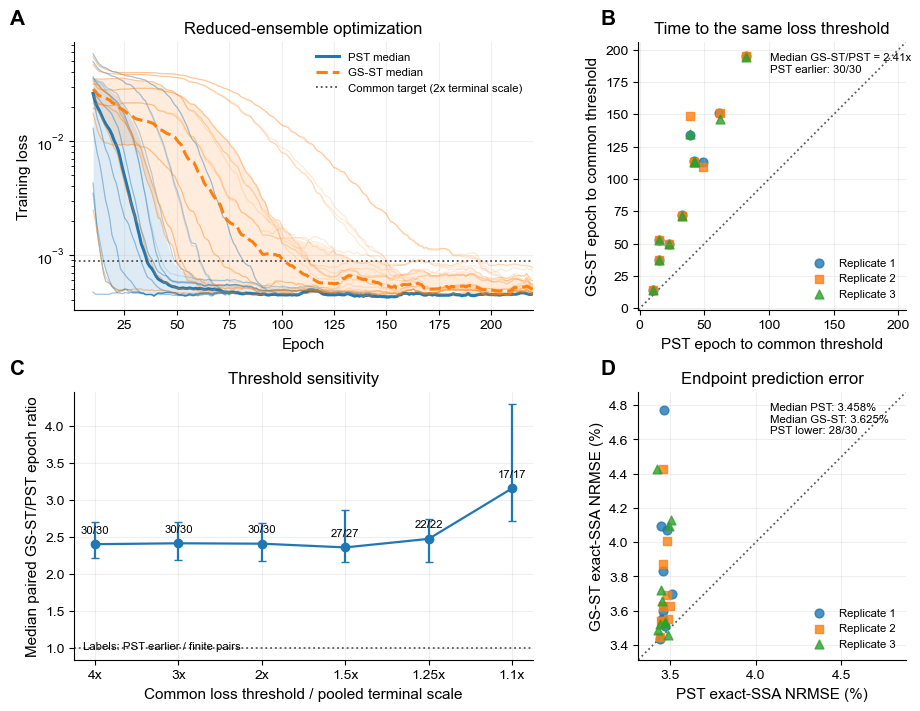

In [ ]:
# =============================================================================
# 13. Main-text Figure 5
#     Plotting style matched to IonChannel-PST.ipynb
# =============================================================================

# These rcParams intentionally match IonChannel-PST.ipynb.
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 11,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "lines.linewidth": 1.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)

_COLOR_CYCLE = plt.rcParams["axes.prop_cycle"].by_key()["color"]
PST_COLOR = _COLOR_CYCLE[0]
GSST_COLOR = _COLOR_CYCLE[1]
REPLICATE_MARKERS = ("o", "s", "^", "D", "v")


def _panel_label(ax, label):
    """Panel labels matched to IonChannel-PST.ipynb."""
    ax.text(
        -0.14,
        1.05,
        label,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )


def smoothed_loss_curve(results):
    loss = np.asarray(results["loss_hist"], dtype=float)
    smooth = moving_median(
        loss,
        min(CFG.common_loss_smooth_window, loss.size),
    )
    epochs = np.arange(CFG.common_loss_smooth_window, loss.size + 1)
    return epochs, smooth


def _scatter_by_replicate(ax, x, y, paired, size=40):
    """
    Direct paired scatter.

    Marker shape identifies replicate. Replicates use the first colors of the
    same Matplotlib color cycle used by IonChannel-PST.ipynb.
    """
    for j, (replicate, group) in enumerate(paired.groupby("replicate")):
        idx = group.index.to_numpy()
        ax.scatter(
            x[idx],
            y[idx],
            s=size,
            marker=REPLICATE_MARKERS[j % len(REPLICATE_MARKERS)],
            color=_COLOR_CYCLE[j % len(_COLOR_CYCLE)],
            alpha=0.80,
            label=f"Replicate {int(replicate) + 1}",
        )


def _square_identity_axes(ax, x, y, pad_fraction=0.06):
    """
    Give equivalent x/y quantities identical limits and a square plotting box.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    finite = np.isfinite(x) & np.isfinite(y)
    if not np.any(finite):
        return

    lo = min(np.min(x[finite]), np.min(y[finite]))
    hi = max(np.max(x[finite]), np.max(y[finite]))
    span = max(hi - lo, 1e-12)
    pad = pad_fraction * span

    lo_plot = lo - pad
    hi_plot = hi + pad

    ax.plot(
        [lo_plot, hi_plot],
        [lo_plot, hi_plot],
        linestyle=":",
        linewidth=1.3,
        color="0.35",
        zorder=0,
    )
    ax.set_xlim(lo_plot, hi_plot)
    ax.set_ylim(lo_plot, hi_plot)

    # Equal data units plus a square physical axes box.
    ax.set_aspect("equal", adjustable="box")
    ax.set_box_aspect(1)


def build_main_text_figure():
    # Match the 2x2 comparison-figure dimensions used in IonChannel-PST.ipynb.
    fig = plt.figure(figsize=(10, 7), layout="constrained")
    grid = fig.add_gridspec(2, 2)

    ax_a = fig.add_subplot(grid[0, 0])
    ax_b = fig.add_subplot(grid[0, 1])
    ax_c = fig.add_subplot(grid[1, 0])
    ax_d = fig.add_subplot(grid[1, 1])

    # -----------------------------------------------------------------
    # A. Actual rolling-median training loss.
    # Thin lines: individual runs. Thick lines + bands: median + IQR.
    # -----------------------------------------------------------------
    method_styles = {
        "PST": {
            "label": "PST",
            "color": PST_COLOR,
            "linestyle": "-",
        },
        "GSST": {
            "label": "GS-ST",
            "color": GSST_COLOR,
            "linestyle": "--",
        },
    }

    for method in ("PST", "GSST"):
        style = method_styles[method]
        curves = []
        epochs_ref = None

        for _, row in PAIRED[["init_id", "replicate"]].iterrows():
            init_id = int(row["init_id"])
            replicate = int(row["replicate"])
            results = RUN_RECORDS[(init_id, replicate, method)]["results"]

            epochs, smooth = smoothed_loss_curve(results)
            epochs_ref = epochs
            curves.append(smooth)

            ax_a.plot(
                epochs,
                np.maximum(smooth, np.finfo(float).tiny),
                color=style["color"],
                alpha=0.18,
                linewidth=0.8,
                label="_nolegend_",
            )

        curves = np.vstack(curves)
        median_curve = np.nanmedian(curves, axis=0)
        q25 = np.nanpercentile(curves, 25, axis=0)
        q75 = np.nanpercentile(curves, 75, axis=0)

        ax_a.fill_between(
            epochs_ref,
            np.maximum(q25, np.finfo(float).tiny),
            np.maximum(q75, np.finfo(float).tiny),
            color=style["color"],
            alpha=0.14,
            linewidth=0,
        )
        ax_a.plot(
            epochs_ref,
            np.maximum(median_curve, np.finfo(float).tiny),
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=2.2,
            label=f"{style['label']} median",
        )

    ax_a.axhline(
        PRIMARY_LOSS_TARGET,
        color="0.30",
        linestyle=":",
        linewidth=1.3,
        label=(
            f"Common target "
            f"({CFG.common_loss_primary_multiplier:g}x terminal scale)"
        ),
    )

    ax_a.set_yscale("log")
    ax_a.set_xlim(1, 220)
    ax_a.set_xlabel("Epoch")
    ax_a.set_ylabel("Training loss")
    ax_a.set_title("Reduced-ensemble optimization")
    ax_a.grid(True, alpha=0.2)
    ax_a.legend(frameon=False, fontsize=8.2, loc="upper right")
    _panel_label(ax_a, "A")

    # -----------------------------------------------------------------
    # B. Direct GS-ST versus PST time-to-threshold comparison.
    # Equivalent quantities -> square panel with identical x/y limits.
    # Above identity -> PST reaches the common target earlier.
    # -----------------------------------------------------------------
    x_epoch = PAIRED["common_target_epoch_PST"].to_numpy(float)
    y_epoch = PAIRED["common_target_epoch_GSST"].to_numpy(float)

    _scatter_by_replicate(ax_b, x_epoch, y_epoch, PAIRED, size=40)
    _square_identity_axes(ax_b, x_epoch, y_epoch, pad_fraction=0.06)

    ratio = PAIRED["common_epoch_ratio_GSST_over_PST"].to_numpy(float)

    ax_b.set_xlabel("PST epoch to common threshold")
    ax_b.set_ylabel("GS-ST epoch to common threshold")
    ax_b.set_title("Time to the same loss threshold")
    ax_b.grid(True, alpha=0.2)
    ax_b.legend(frameon=False, fontsize=8.2, loc="lower right")
    _panel_label(ax_b, "B")

    ax_b.text(
        0.04+0.45,
        0.96,
        (
            f"Median GS-ST/PST = {finite_median(ratio):.2f}x\n"
            f"PST earlier: {np.sum(ratio > 1)}/"
            f"{np.sum(np.isfinite(ratio))}"
        ),
        transform=ax_b.transAxes,
        ha="left",
        va="top",
        fontsize=8.2,
    )

    # -----------------------------------------------------------------
    # C. Sensitivity of the paired ratio to the common threshold.
    # -----------------------------------------------------------------
    multipliers = np.asarray(
        CFG.common_loss_target_multipliers,
        dtype=float,
    )

    medians = []
    q25s = []
    q75s = []
    finite_counts = []
    win_counts = []

    for multiplier in multipliers:
        values = paired_common_target_arrays(
            multiplier,
            CFG.common_loss_primary_persistence,
        )
        r = values["epoch_ratio"]
        medians.append(finite_median(r))
        q25, q75 = finite_iqr(r)
        q25s.append(q25)
        q75s.append(q75)
        finite_counts.append(int(np.sum(np.isfinite(r))))
        win_counts.append(int(np.sum(r > 1)))

    medians = np.asarray(medians, dtype=float)
    q25s = np.asarray(q25s, dtype=float)
    q75s = np.asarray(q75s, dtype=float)

    x = np.arange(len(multipliers))

    ax_c.errorbar(
        x,
        medians,
        yerr=np.vstack([medians - q25s, q75s - medians]),
        color=PST_COLOR,
        marker="o",
        capsize=3,
        linewidth=1.6,
    )
    ax_c.axhline(
        1.0,
        color="0.35",
        linestyle=":",
        linewidth=1.3,
    )

    for xi, median, nwin, nfinite in zip(
        x, medians, win_counts, finite_counts
    ):
        ax_c.annotate(
            f"{nwin}/{nfinite}",
            (xi, median),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=8.2,
        )

    labels = [f"{m:g}x" for m in multipliers]
    ax_c.set_xticks(x, labels)
    ax_c.set_xlabel("Common loss threshold / pooled terminal scale")
    ax_c.set_ylabel("Median paired GS-ST/PST epoch ratio")
    ax_c.set_title("Threshold sensitivity")
    ax_c.grid(True, alpha=0.2)
    _panel_label(ax_c, "C")

    ax_c.text(
        0.02,
        0.04,
        "Labels: PST earlier / finite pairs",
        transform=ax_c.transAxes,
        fontsize=8.2,
    )

    # -----------------------------------------------------------------
    # D. Direct GS-ST versus PST independent exact-SSA endpoint NRMSE.
    # Equivalent quantities -> square panel with identical x/y limits.
    # Above identity -> PST has lower endpoint error.
    # -----------------------------------------------------------------
    x_nrmse = 100.0 * PAIRED["nrmse_PST"].to_numpy(float)
    y_nrmse = 100.0 * PAIRED["nrmse_GSST"].to_numpy(float)

    _scatter_by_replicate(ax_d, x_nrmse, y_nrmse, PAIRED, size=40)
    _square_identity_axes(ax_d, x_nrmse, y_nrmse, pad_fraction=0.08)

    ax_d.set_xlabel("PST exact-SSA NRMSE (%)")
    ax_d.set_ylabel("GS-ST exact-SSA NRMSE (%)")
    ax_d.set_title("Endpoint prediction error")
    ax_d.grid(True, alpha=0.2)
    ax_d.legend(frameon=False, fontsize=8.2, loc="lower right")
    _panel_label(ax_d, "D")

    ax_d.text(
        0.04+0.45,
        0.96,
        (
            f"Median PST: {finite_median(x_nrmse):.3f}%\n"
            f"Median GS-ST: {finite_median(y_nrmse):.3f}%\n"
            f"PST lower: {np.sum(x_nrmse < y_nrmse)}/"
            f"{np.sum(np.isfinite(x_nrmse) & np.isfinite(y_nrmse))}"
        ),
        transform=ax_d.transAxes,
        ha="left",
        va="top",
        fontsize=8.2,
    )

    # Save exactly the same three formats and with the same export treatment
    # used in IonChannel-PST.ipynb.
    prefix = ANALYSIS_DIR / "Figure_main_ion_channel_resource_efficient"
    for extension in (".pdf", ".svg", ".png"):
        filepath = Path(str(prefix) + extension)
        plt.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
            transparent=(extension != ".png"),
        )
        print(f"Saved {Path(filepath).name}")

    return fig


MAIN_TEXT_FIGURE = build_main_text_figure()
plt.show()


Saved parameter-robustness SI figure:
  Figure_S_ion_channel_initialization_robustness.pdf
  Figure_S_ion_channel_initialization_robustness.png


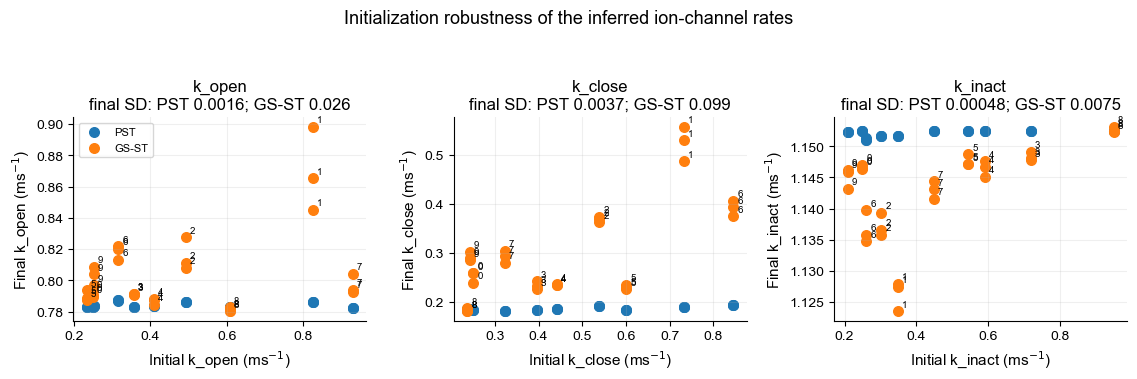

In [ ]:
# =============================================================================
# 14. SI figure: robustness of inferred kinetic rates to starting parameters
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.8))

for ax, rate in zip(axes, RATE_NAMES):
    initial = PAIRED[f"initial_{rate}_PST"].to_numpy(float)
    pst_final = PAIRED[f"final_{rate}_PST"].to_numpy(float)
    gsst_final = PAIRED[f"final_{rate}_GSST"].to_numpy(float)

    ax.scatter(
        initial,
        pst_final,
        s=48,
        label="PST",
    )
    ax.scatter(
        initial,
        gsst_final,
        s=48,
        label="GS-ST",
    )

    for i, init_id in enumerate(PAIRED["init_id"].to_numpy(int)):
        ax.annotate(
            str(init_id),
            (initial[i], gsst_final[i]),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=7,
        )

    ax.set_xlabel(f"Initial {rate} (ms$^{{-1}}$)")
    ax.set_ylabel(f"Final {rate} (ms$^{{-1}}$)")
    ax.set_title(
        f"{rate}\n"
        f"final SD: PST {np.std(pst_final, ddof=1):.2g}; "
        f"GS-ST {np.std(gsst_final, ddof=1):.2g}"
    )
    ax.grid(alpha=0.20)

axes[0].legend(fontsize=8)

fig.suptitle(
    "Initialization robustness of the inferred ion-channel rates",
    y=0.99,
    fontsize=13,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))

pdf_path = ANALYSIS_DIR / "Figure_S_ion_channel_initialization_robustness.pdf"
png_path = ANALYSIS_DIR / "Figure_S_ion_channel_initialization_robustness.png"

fig.savefig(pdf_path, bbox_inches="tight")
fig.savefig(png_path, dpi=300, bbox_inches="tight")

print("Saved parameter-robustness SI figure:")
print(" ", pdf_path.name)
print(" ", png_path.name)

plt.show()


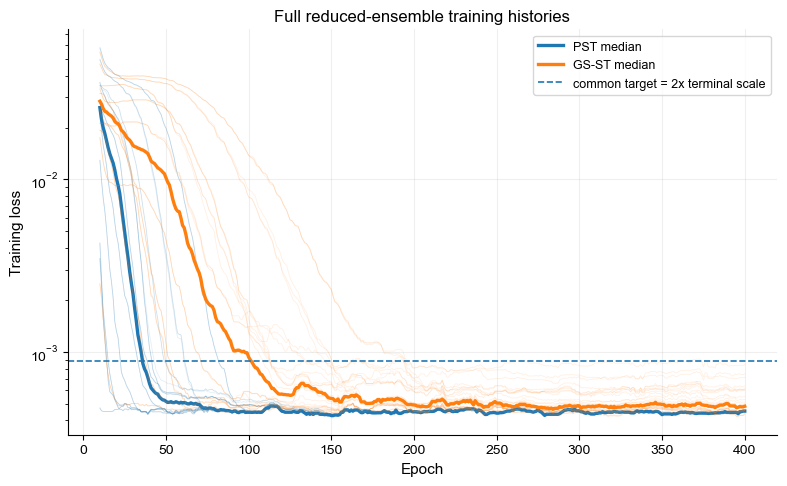

In [ ]:
# =============================================================================
# 15. Optional full 400-epoch loss-history overview
# =============================================================================

fig, ax = plt.subplots(figsize=(8.0, 5.0))

for method in ("PST", "GSST"):
    curves = []
    epochs_ref = None
    method_color = None

    for _, row in PAIRED[["init_id", "replicate"]].iterrows():
        results = RUN_RECORDS[
            (
                int(row["init_id"]),
                int(row["replicate"]),
                method,
            )
        ]["results"]

        epochs, smooth = smoothed_loss_curve(results)
        epochs_ref = epochs
        curves.append(smooth)

        if method_color is None:
            line = ax.plot(
                epochs,
                smooth,
                alpha=0.12,
                linewidth=0.55,
            )[0]
            method_color = line.get_color()
        else:
            ax.plot(
                epochs,
                smooth,
                alpha=0.12,
                linewidth=0.55,
                color=method_color,
            )

    curves = np.vstack(curves)
    median_curve = np.nanmedian(curves, axis=0)
    display_name = "GS-ST" if method == "GSST" else "PST"

    ax.plot(
        epochs_ref,
        median_curve,
        linewidth=2.4,
        color=method_color,
        label=f"{display_name} median",
    )

ax.axhline(
    PRIMARY_LOSS_TARGET,
    linestyle="--",
    linewidth=1.2,
    label=(
        f"common target = "
        f"{CFG.common_loss_primary_multiplier:g}x terminal scale"
    ),
)

ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training loss")
ax.set_title("Full reduced-ensemble training histories")
ax.legend()
ax.grid(alpha=0.20)

fig.tight_layout()
plt.show()


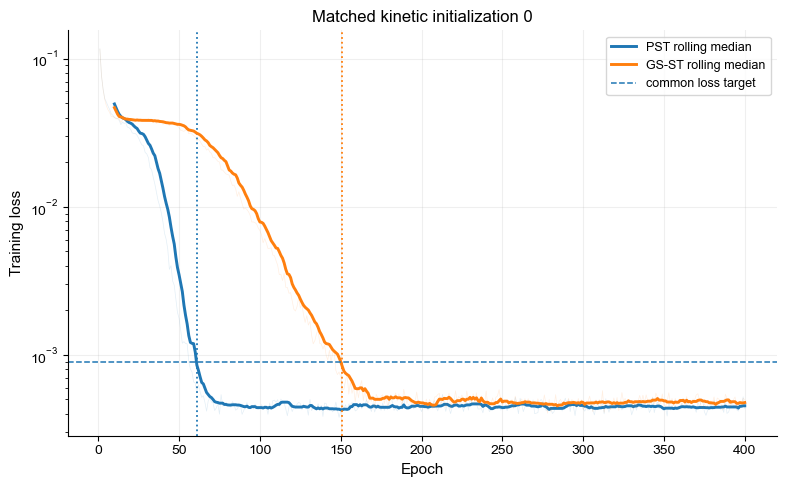

In [ ]:
# =============================================================================
# 16. Inspect one matched initialization
# =============================================================================

def plot_history(init_id, replicate=0):
    fig, ax = plt.subplots(figsize=(8.0, 5.0))

    for method in ("PST", "GSST"):
        results = RUN_RECORDS[
            (int(init_id), int(replicate), method)
        ]["results"]

        display_name = "GS-ST" if method == "GSST" else "PST"
        loss = np.asarray(results["loss_hist"], dtype=float)
        raw_epoch = np.arange(1, loss.size + 1)
        epochs, smooth = smoothed_loss_curve(results)

        line = ax.plot(
            raw_epoch,
            loss,
            alpha=0.12,
            linewidth=0.5,
        )[0]
        color = line.get_color()

        ax.plot(
            epochs,
            smooth,
            linewidth=2.1,
            color=color,
            label=f"{display_name} rolling median",
        )

        metric = common_loss_entry_metrics(
            results,
            target_loss=PRIMARY_LOSS_TARGET,
            cfg=CFG,
            persistence=CFG.common_loss_primary_persistence,
        )

        if metric["onset_epoch"] is not None:
            ax.axvline(
                metric["onset_epoch"],
                linestyle=":",
                linewidth=1.3,
                color=color,
            )

    ax.axhline(
        PRIMARY_LOSS_TARGET,
        linestyle="--",
        linewidth=1.1,
        label="common loss target",
    )

    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training loss")
    ax.set_title(f"Matched kinetic initialization {init_id}")
    ax.legend()
    ax.grid(alpha=0.20)

    fig.tight_layout()
    plt.show()


plot_history(0)


In [ ]:
# =============================================================================
# 17. Export figure data and results summary
# =============================================================================

primary = paired_common_target_arrays(
    CFG.common_loss_primary_multiplier,
    CFG.common_loss_primary_persistence,
)

FIGURE_DATA = PAIRED[
    [
        "init_id",
        "replicate",
        "initial_k_open_PST",
        "initial_k_close_PST",
        "initial_k_inact_PST",
        "final_k_open_PST",
        "final_k_open_GSST",
        "final_k_close_PST",
        "final_k_close_GSST",
        "final_k_inact_PST",
        "final_k_inact_GSST",
        "nrmse_PST",
        "nrmse_GSST",
        "r_squared_PST",
        "r_squared_GSST",
    ]
].copy()

FIGURE_DATA["primary_loss_target"] = PRIMARY_LOSS_TARGET
FIGURE_DATA["primary_PST_epoch"] = primary["pst_epoch"]
FIGURE_DATA["primary_GSST_epoch"] = primary["gsst_epoch"]
FIGURE_DATA["primary_GSST_over_PST_ratio"] = primary["epoch_ratio"]

FIGURE_DATA.to_csv(
    ANALYSIS_DIR
    / "Figure_S_ion_channel_reduced_ensemble_actual_results_data.csv",
    index=False,
)

print("RESULTS SUMMARY")
print("-------------------------")
print(
    f"Training ensemble: {CFG.trajectories_per_epoch:,} trajectories/epoch, "
    f"{CFG.ssa_steps} SSA event slots, {CFG.epochs} epochs."
)
print(
    f"Common terminal loss scale: {COMMON_TERMINAL_SCALE:.6g}; "
    f"primary target: {PRIMARY_LOSS_TARGET:.6g} "
    f"({CFG.common_loss_primary_multiplier:g}x)."
)
print(
    f"Median epoch to common target: "
    f"PST {finite_median(primary['pst_epoch']):.1f}, "
    f"GS-ST {finite_median(primary['gsst_epoch']):.1f}."
)
print(
    f"Median paired GS-ST/PST epoch ratio: "
    f"{finite_median(primary['epoch_ratio']):.3f}; "
    f"PST earlier in {np.sum(primary['epoch_ratio'] > 1)}/"
    f"{np.sum(np.isfinite(primary['epoch_ratio']))} pairs."
)
print(
    f"Median validation NRMSE: "
    f"PST {finite_median(100*PAIRED['nrmse_PST']):.3f}%, "
    f"GS-ST {finite_median(100*PAIRED['nrmse_GSST']):.3f}%."
)


print("\nPer-replicate median paired ratios")
for replicate, group in PAIRED.groupby("replicate"):
    ratios = group["common_epoch_ratio_GSST_over_PST"].to_numpy(float)
    print(
        f"  replicate {int(replicate) + 1}: "
        f"{finite_median(ratios):.3f} "
        f"({np.sum(ratios > 1)}/{np.sum(np.isfinite(ratios))} PST earlier)"
    )


RESULTS SUMMARY
-------------------------
Training ensemble: 10,000 trajectories/epoch, 40 SSA event slots, 400 epochs.
Common terminal loss scale: 0.000445509; primary target: 0.000891018 (2x).
Median epoch to common target: PST 36.0, GS-ST 90.5.
Median paired GS-ST/PST epoch ratio: 2.407; PST earlier in 30/30 pairs.
Median validation NRMSE: PST 3.458%, GS-ST 3.625%.

Per-replicate median paired ratios
  replicate 1: 2.422 (10/10 PST earlier)
  replicate 2: 2.407 (10/10 PST earlier)
  replicate 3: 2.416 (10/10 PST earlier)
